# Exploratie: hotelboekingen

Wat zit er in de data, wat is er stuk aan, en wat is eraan gedaan? Dit notebook verantwoordt de
keuzes in `src/`. Het verandert zelf niets: alle opschoning gebeurt in de code (`src/data.py`,
`src/schema.py`), zodat training en voorspellen dezelfde stappen doorlopen.

1. Wat zit erin
2. Wat is stuk, en wat is eraan gedaan
3. Non Refund: eerst uitzoeken, dan uitsluiten
4. Het label: wie is actief op het beslismoment
5. Lekcontrole per kolom
6. Het land
7. De capaciteit per hotel
8. De spreiding per nacht: annulaties komen samen
9. Indirecte kenmerken: verwijzen segment en agent naar het land?
10. Lek via adr: geboekt tarief of achteraf aangepast?
11. Wat dit betekent voor het model

Draai het vanuit de projectmap of vanuit `notebooks/`.

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))

In [2]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src.config import invoerkolommen, laad_config
from src.data import aankomstdatum, bereid_voor, laad_data, schoon_op
from src.kenmerken import als_tekst
from src.nachten import bezetting, capaciteit
from src.train import grenzen, splits, train, valideer

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# Eén kleur per hotel, altijd dezelfde. Rustige assen.
KLEUR = {"City Hotel": "#2a78d6", "Resort Hotel": "#eb6834"}
INKT, INKT_ZACHT, RASTER = "#1f1f1e", "#5f5e58", "#e4e3df"


def opmaak(ax, titel=None):
    ax.grid(True, color=RASTER, linewidth=0.8)
    ax.set_axisbelow(True)
    for kant in ["top", "right"]:
        ax.spines[kant].set_visible(False)
    for kant in ["left", "bottom"]:
        ax.spines[kant].set_color(RASTER)
    ax.tick_params(colors=INKT_ZACHT, labelsize=9)
    if titel:
        ax.set_title(titel, color=INKT, fontsize=11, loc="left")


cfg = laad_config(PROJECT / "configs" / "default.yaml")
DOEL = cfg["doel"]

## 1. Wat zit erin

*Hotel booking demand* (Antonio, de Almeida & Nunes, 2019): boekingen van een stadshotel in
Lissabon en een resort in de Algarve. Eén rij per boeking, met wat bij het boeken gekend is en de
afloop (`is_canceled`, `reservation_status`, `reservation_status_date`). Er is geen boekingsnummer.

`laad_data` valideert meteen tegen het Pandera-schema. Wat het schema niet haalt, komt hier niet
voorbij.

In [3]:
ruw = laad_data(cfg["data"]["pad"])
print(f"{len(ruw):_} boekingen, {ruw.shape[1]} kolommen".replace("_", " "))
aankomst = aankomstdatum(ruw)
print(f"aankomst van {aankomst.min():%d-%m-%Y} tot {aankomst.max():%d-%m-%Y}")
ruw.head(3).T

119 390 boekingen, 32 kolommen
aankomst van 01-07-2015 tot 31-08-2017


,0,1,2
hotel,Resort Hotel,Resort Hotel,Resort Hotel
is_canceled,0,0,0
lead_time,342,737,7
arrival_date_year,2015,2015,2015
arrival_date_month,July,July,July
arrival_date_week_number,27,27,27
arrival_date_day_of_month,1,1,1
stays_in_weekend_nights,0,0,0
stays_in_week_nights,0,0,1
adults,2,2,1


In [4]:
per_hotel = ruw.groupby("hotel").agg(
    boekingen=("hotel", "size"),
    annuleert=("is_canceled", "mean"),
    lead_time_mediaan=("lead_time", "median"),
    adr_mediaan=("adr", "median"),
)
per_hotel.round(3)

,boekingen,annuleert,lead_time_mediaan,adr_mediaan
hotel,,,,
City Hotel,79330,0.417,74.0,99.9
Resort Hotel,40060,0.278,57.0,75.0


37 % van alle boekingen annuleert, City vaker dan Resort. Het schema eist dat dat aandeel tussen
20 en 50 % ligt: een export met alleen annulaties of zonder annulaties wordt geweigerd.

Annuleren verandert met het seizoen en over de jaren: City begint in juli 2015 op 67 % en zakt
dan, Resort klimt in 2017 tot boven City. Dat is de reden voor een split in de tijd: een
willekeurige split laat het model leren van maanden die op het beslismoment nog moeten komen.

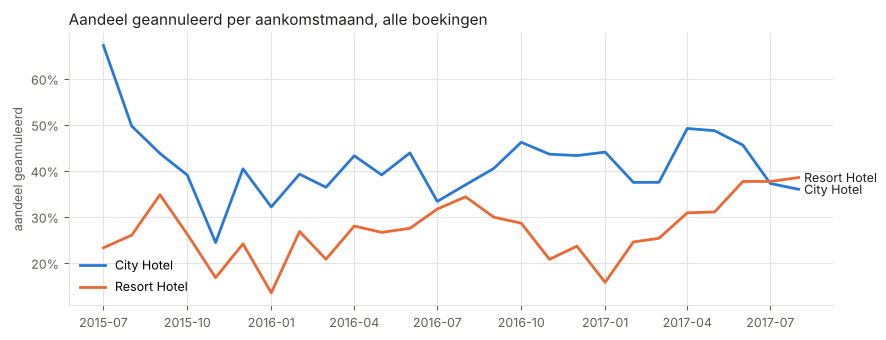

In [5]:
maand = aankomst.dt.to_period("M").dt.to_timestamp()
reeks = ruw.groupby([maand, "hotel"])["is_canceled"].mean().unstack()

fig, ax = plt.subplots(figsize=(9, 3.5))
for hotel in reeks.columns:
    ax.plot(reeks.index, reeks[hotel], color=KLEUR[hotel], linewidth=2, label=hotel)
    ax.annotate(
        hotel,
        (reeks.index[-1], reeks[hotel].iloc[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        color=INKT,
        fontsize=9,
        va="center",
    )
ax.set_ylabel("aandeel geannuleerd", color=INKT_ZACHT, fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, fontsize=9, loc="lower left")
opmaak(ax, "Aandeel geannuleerd per aankomstmaand, alle boekingen")
plt.tight_layout()

## 2. Wat is stuk, en wat is eraan gedaan

| Probleem | Hoeveel | Wat ermee gebeurt | Waar |
|---|---|---|---|
| `children` leeg | 4 | ingevuld met de mediaan, in de pijplijn | `src/train.py` |
| `country` leeg | 488 | het land is geen feature (zie 6) | `configs/default.yaml` |
| `agent` leeg | 16 340 | betekent "zonder agent": eigen categorie `geen` | `src/kenmerken.py` |
| `company` leeg | 112 593 (94 %) | niet gebruikt | |
| `adr` ≤ 0 | 1 960 | uitgesloten: geen echte verkoop | `schoon_op()` |
| `adr` ≥ 1 000 | 1 (5 400 €) | uitgesloten: een tikfout | `schoon_op()` |
| 0 nachten | 715 | uitgesloten: geen hotel-nacht om te tellen | `schoon_op()` |
| 0 personen | 180 | laten staan: het schema laat het toe, het model ziet het | |
| `Undefined` in `meal`, `market_segment`, `distribution_channel` | 1 169, 2, 5 | eigen categorie | |
| Non Refund, 99,4 % geannuleerd | 14 587 | uitgesloten, na onderzoek (zie 3) | `schoon_op()` |
| exacte dubbele rijen | 31 994 (27 %) | laten staan (zie hieronder) | |

De cijfers hieronder rekenen de tabel na.

In [6]:
nachten = ruw["stays_in_weekend_nights"] + ruw["stays_in_week_nights"]
personen = ruw["adults"] + ruw["children"].fillna(0) + ruw["babies"]
pd.Series(
    {
        "children leeg": ruw["children"].isna().sum(),
        "country leeg": ruw["country"].isna().sum(),
        "agent leeg": ruw["agent"].isna().sum(),
        "company leeg": ruw["company"].isna().sum(),
        "adr <= 0": (ruw["adr"] <= 0).sum(),
        "adr >= 1000": (ruw["adr"] >= 1000).sum(),
        "0 nachten": (nachten == 0).sum(),
        "0 personen": (personen == 0).sum(),
        "meal Undefined": (ruw["meal"] == "Undefined").sum(),
        "Non Refund": (ruw["deposit_type"] == "Non Refund").sum(),
        "exacte dubbele rijen": ruw.duplicated().sum(),
    },
    name="aantal",
).to_frame()

,aantal
children leeg,4
country leeg,488
agent leeg,16340
company leeg,112593
adr <= 0,1960
adr >= 1000,1
0 nachten,715
0 personen,180
meal Undefined,1169
Non Refund,14587


**Dubbele rijen.** Een kwart van de rijen is een exacte kopie van een andere. Er is geen
boekingsnummer, dus een kopie is niet te onderscheiden van een tweede kamer in dezelfde
groepsboeking: zelfde aankomst, zelfde agent, zelfde prijs. 72 % van de rijen met een kopie
komt van groepen of touroperators (hieronder). Weggooien zou groepen tot één kamer herleiden en
het aantal kamers per nacht onderschatten. Ze blijven dus staan. Twee gevolgen:

- ze annuleren samen. Dat is de reden voor de spreidingsfactor (zie 8)
- een kopie kan niet in de training en in de test tegelijk zitten: de split gaat op aankomstdatum,
  en kopieën hebben dezelfde aankomst

In [7]:
dubbel = ruw[ruw.duplicated(keep=False)]
print(f"{len(dubbel):_} rijen hebben minstens één kopie".replace("_", " "))
dubbel["market_segment"].value_counts(normalize=True).round(3).head().to_frame("aandeel")

40 165 rijen hebben minstens één kopie


,aandeel
market_segment,
Groups,0.416
Offline TA/TO,0.304
Online TA,0.206
Corporate,0.037
Direct,0.035


## 3. Non Refund: eerst uitzoeken, dan uitsluiten

Wie niet terugbetaald wordt bij annuleren, zou net minder moeten annuleren. In de data is het
omgekeerd: 99,4 % van de Non Refund-boekingen staat als geannuleerd. Dat is geen gedrag, dat is
een eigenaardigheid van de export. Voor het uitsluiten: waar zitten ze?

In [8]:
ruw.groupby("deposit_type")["is_canceled"].agg(["size", "mean"]).round(3)

,size,mean
deposit_type,,
No Deposit,104641,0.284
Non Refund,14587,0.994
Refundable,162,0.222


In [9]:
nr = ruw[ruw["deposit_type"] == "Non Refund"]
alles = ruw
vergelijk = pd.DataFrame(
    {
        "Non Refund": [
            (nr["country"] == "PRT").mean(),
            (nr["hotel"] == "City Hotel").mean(),
            nr["market_segment"].isin(["Groups", "Offline TA/TO"]).mean(),
            (nr["agent"] == 1).mean(),
            nr["lead_time"].median(),
            (nr["reservation_status"] == "Check-Out").sum(),
        ],
        "alle boekingen": [
            (alles["country"] == "PRT").mean(),
            (alles["hotel"] == "City Hotel").mean(),
            alles["market_segment"].isin(["Groups", "Offline TA/TO"]).mean(),
            (alles["agent"] == 1).mean(),
            alles["lead_time"].median(),
            (alles["reservation_status"] == "Check-Out").sum(),
        ],
    },
    index=[
        "aandeel PRT",
        "aandeel City Hotel",
        "aandeel Groups of Offline TA/TO",
        "aandeel agent 1",
        "mediaan lead_time (dagen)",
        "aantal uitgecheckt",
    ],
)
vergelijk.round(3)

,Non Refund,alle boekingen
aandeel PRT,0.972,0.407
aandeel City Hotel,0.882,0.664
aandeel Groups of Offline TA/TO,0.972,0.369
aandeel agent 1,0.279,0.060
mediaan lead_time (dagen),183.000,69.000
aantal uitgecheckt,93.000,75166.000


In [10]:
nr["market_segment"].value_counts().to_frame("boekingen").join(
    nr.groupby("market_segment")["is_canceled"].mean().rename("geannuleerd").round(3)
)

,boekingen,geannuleerd
market_segment,,
Groups,9172,0.993
Offline TA/TO,5006,0.999
Corporate,334,0.934
Online TA,56,0.946
Direct,19,0.842


Non Refund is geen doorsnee van de boekingen: 97 % Portugees, 88 % City Hotel, bijna allemaal
groepen of touroperators, 28 % via één agent (tegenover 6 % van alle boekingen), en een lead
time die bijna drie keer zo lang is. Slechts 93 van de 14 587 checkten uit.

Het past bij een groepsreservering die een touroperator vooraf vastlegt en later grotendeels
vrijgeeft, of bij een systeem dat "Non Refund" als standaard invult. Welke van de twee het is, kan
de data niet zeggen. Wat ze wel zegt: het model zou leren dat Non Refund annuleren betekent, en
dat is voor een echte niet-terugbetaalbare boeking het omgekeerde van de waarheid. Daarom gaat
Non Refund eruit (`opschoning.uitgesloten_deposit`). Het advies geldt dus niet voor die
boekingen. Het hoge aandeel PRT komt terug bij het land (6).

## 4. Het label: wie is actief op het beslismoment

De revenue manager beslist 30 dagen vóór de nacht. Op dat moment telt alleen wat nog actief is:
geboekt vóór het beslismoment en dan nog niet geannuleerd. Het label is of zo'n boeking daarna
alsnog annuleert of een no-show wordt (`maak_label()` in `src/data.py`).

In [11]:
schoon = schoon_op(ruw, cfg)
df = bereid_voor(ruw, cfg)
stappen = pd.Series(
    {
        "ruwe export": len(ruw),
        "na opschoning": len(schoon),
        "actief op het beslismoment": len(df),
    },
    name="boekingen",
)
print(stappen.to_string())
print(f"\nVan de actieve boekingen annuleert {df[DOEL].mean():.1%} nog.")

ruwe export                   119390
na opschoning                 102843
actief op het beslismoment     50824

Van de actieve boekingen annuleert 14.3% nog.


In [12]:
df.groupby("hotel")[DOEL].agg(["size", "mean"]).round(3)

,size,mean
hotel,,
City Hotel,33307,0.157
Resort Hotel,17517,0.117


Van 37 % in de ruwe export naar 14 %: de meeste annulaties gebeuren vroeg, ruim voor het
beslismoment, en die maken geen kamer vrij die het hotel nog moet invullen. Het gaat om de late
annulaties en de no-shows.

## 5. Lekcontrole per kolom

Een kolom mag alleen een feature zijn als ze gekend is op het beslismoment, 30 dagen vóór de
nacht. De tabel zet elke kolom op een rij met een inschatting van wanneer ze ingevuld wordt, en
daarnaast een controle met de data: de AUC als je met die kolom alleen zou voorspellen, geleerd
op de training en gemeten op de validatie. Een categorie krijgt haar annulatiepercentage uit de
training, een getal wordt gewoon gerangschikt. Een uitschieter ten opzichte van de rest is
verdacht.

In [13]:
delen = splits(df, cfg)
training, validatie = delen["training"], delen["validatie"]


def auc_alleen(kolom):
    a, b = training[kolom], validatie[kolom]
    if a.dtype.kind in "if" and a.nunique() > 20:
        score = b.fillna(a.median())
        auc = roc_auc_score(validatie[DOEL], score)
        return max(auc, 1 - auc)
    percentage = training.groupby(a.astype(str))[DOEL].mean()
    score = b.astype(str).map(percentage).fillna(training[DOEL].mean())
    return roc_auc_score(validatie[DOEL], score)


GEKEND = {
    "hotel": ("bij boeking", "ja", ""),
    "lead_time": ("bij boeking", "ja", ""),
    "arrival_date_year": ("bij boeking", "nee", "een jaar komt nooit terug; wel voor de split"),
    "arrival_date_month": ("bij boeking", "ja", "seizoen"),
    "arrival_date_week_number": ("bij boeking", "nee", "zegt hetzelfde als de maand, fijner"),
    "arrival_date_day_of_month": ("bij boeking", "nee", "alleen voor de datum"),
    "stays_in_weekend_nights": ("bij boeking, kan wijzigen", "ja", ""),
    "stays_in_week_nights": ("bij boeking, kan wijzigen", "ja", ""),
    "adults": ("bij boeking", "ja", ""),
    "children": ("bij boeking", "ja", ""),
    "babies": ("bij boeking", "ja", ""),
    "meal": ("bij boeking", "ja", ""),
    "country": ("waarschijnlijk bij inchecken", "nee", "lek, zie 6"),
    "market_segment": ("bij boeking", "ja", ""),
    "distribution_channel": ("bij boeking", "ja", ""),
    "is_repeated_guest": ("bij boeking", "ja", ""),
    "previous_cancellations": ("bij boeking", "ja", ""),
    "previous_bookings_not_canceled": ("bij boeking", "ja", ""),
    "reserved_room_type": ("bij boeking", "ja", ""),
    "assigned_room_type": ("bij inchecken", "nee", "lek"),
    "booking_changes": ("telt tot aankomst", "nee", "lek"),
    "deposit_type": ("bij boeking", "ja", "na het weglaten van Non Refund bijna constant"),
    "agent": ("bij boeking", "ja", ""),
    "company": ("bij boeking", "nee", "94 % leeg"),
    "days_in_waiting_list": ("tot bevestiging, moment onbekend", "nee", "twijfel, dus niet"),
    "customer_type": ("bij boeking", "ja", ""),
    "adr": ("bij boeking, kan wijzigen", "ja", "geen verdacht signaal"),
    "required_car_parking_spaces": ("bij aankomst", "nee", "lek"),
    "total_of_special_requests": ("telt tot aankomst", "nee", "lek"),
    "reservation_status": ("de afloop", "nee", "het label"),
    "reservation_status_date": ("de afloop", "nee", "het label"),
}
lekcontrole = pd.DataFrame(
    [
        {"kolom": k, "gekend": g, "feature": f, "AUC alleen": auc_alleen(k), "opmerking": o}
        for k, (g, f, o) in GEKEND.items()
    ]
).sort_values("AUC alleen", ascending=False)
lekcontrole.round(3).reset_index(drop=True)

,kolom,gekend,feature,AUC alleen,opmerking
0,reservation_status,de afloop,nee,1.000,het label
1,country,waarschijnlijk bij inchecken,nee,0.662,"lek, zie 6"
2,arrival_date_week_number,bij boeking,nee,0.602,"zegt hetzelfde als de maand, fijner"
3,lead_time,bij boeking,ja,0.577,
4,agent,bij boeking,ja,0.565,
5,meal,bij boeking,ja,0.563,
6,customer_type,bij boeking,ja,0.560,
7,adr,"bij boeking, kan wijzigen",ja,0.557,geen verdacht signaal
8,total_of_special_requests,telt tot aankomst,nee,0.546,lek
9,assigned_room_type,bij inchecken,nee,0.539,lek


In [14]:
# Klopt de lijst in de config met de lekcontrole?
features = set(cfg["features"]["numeriek"] + cfg["features"]["categorisch"])
gekend_ja = set(lekcontrole.loc[lekcontrole["feature"] == "ja", "kolom"])
assert features == gekend_ja, features ^ gekend_ja
print("De features in configs/default.yaml zijn precies de kolommen met 'ja'.")

De features in configs/default.yaml zijn precies de kolommen met 'ja'.


Vier dingen vallen op.

- **Het label zelf** haalt 1,000. Zo hoort een lek eruit te zien, en dat is ook de controle dat
  de methode werkt.
- **Het land** is met afstand de sterkste kolom, sterker dan `lead_time`, die in elke studie over
  annulaties bovenaan staat. Daarover gaat 6.
- **Het weeknummer** scoort 0,60, de maand maar 0,52. Het is gekend bij het boeken, dus geen lek.
  Het vat het seizoen fijner, maar kan ook toevallig groepen vangen die in dezelfde weken van
  2016 en 2017 annuleerden. Het is een kandidaat-feature, nog niet getest.
- **De kolommen die pas na het beslismoment ingevuld worden** scoren hier niet hoog, en toch zijn
  het lekken. De AUC meet alleen hoe goed een kolom rangschikt over alle boekingen. Een lek dat
  maar in één richting werkt, verdwijnt daarin. Een parkeerplaats is daar het duidelijkste
  voorbeeld van:

In [15]:
def annuleert_als(masker, wat):
    return {"wat": wat, "boekingen": int(masker.sum()), "annuleert": df.loc[masker, DOEL].mean()}


pd.DataFrame(
    [
        annuleert_als(df["required_car_parking_spaces"] > 0, "met parkeerplaats"),
        annuleert_als(
            df["assigned_room_type"] != df["reserved_room_type"], "andere kamer gekregen"
        ),
        annuleert_als(df["total_of_special_requests"] > 0, "met speciale wensen"),
        annuleert_als(pd.Series(True, index=df.index), "alle actieve boekingen"),
    ]
).round(3)

,wat,boekingen,annuleert
0,met parkeerplaats,3265,0.000
1,andere kamer gekregen,6923,0.041
2,met speciale wensen,26410,0.107
3,alle actieve boekingen,50824,0.143


Van de 3 265 actieve boekingen met een parkeerplaats annuleert er niet één. Dat is geen
eigenschap van automobilisten: de parkeerplaats wordt bij aankomst ingevuld, en wie annuleert,
komt niet aan. Hetzelfde voor een andere kamer dan gereserveerd, die je pas bij het inchecken
krijgt. Al die kolommen blijven buiten het model, ook al zou een model ze graag gebruiken.

## 6. Het land

Volgens de lekcontrole is het land de sterkste kolom. In het voorstel stond het als feature,
gegroepeerd tot PRT tegenover de rest. Voor het dat mag zijn: wanneer wordt het ingevuld?

In [16]:
prt = df["country"] == "PRT"
df.groupby("reservation_status")["country"].apply(lambda c: (c == "PRT").mean()).round(3).to_frame(
    "aandeel PRT"
)

,aandeel PRT
reservation_status,
Canceled,0.515
Check-Out,0.182
No-Show,0.630


In [17]:
per_segment = pd.DataFrame(
    {
        "PRT bij wie uitcheckte": df[df[DOEL] == 0]
        .groupby("market_segment")["country"]
        .apply(lambda c: (c == "PRT").mean()),
        "PRT bij wie annuleerde": df[df[DOEL] == 1]
        .groupby("market_segment")["country"]
        .apply(lambda c: (c == "PRT").mean()),
        "annuleert, PRT": df[prt].groupby("market_segment")[DOEL].mean(),
        "annuleert, rest": df[~prt].groupby("market_segment")[DOEL].mean(),
        "boekingen": df.groupby("market_segment").size(),
    }
)
per_segment.round(3)

,PRT bij wie uitcheckte,PRT bij wie annuleerde,"annuleert, PRT","annuleert, rest",boekingen
market_segment,,,,,
Complementary,0.550,1.000,0.214,0.000,23
Corporate,0.521,0.940,0.264,0.024,809
Direct,0.280,0.540,0.187,0.071,4487
Groups,0.262,0.993,0.425,0.002,7126
Offline TA/TO,0.200,0.894,0.299,0.012,13111
Online TA,0.119,0.288,0.334,0.144,25268


Als het land bij het boeken ingevuld werd, zou het aandeel Portugezen bij wie annuleert en bij
wie uitcheckt niet zo ver uit elkaar liggen. Dat doet het wel:

- **No-shows** zijn nooit aangekomen, en toch is 63 % Portugees, tegenover 18 % bij wie uitcheckte.
- **Groepen**: 99 % van wie annuleerde is Portugees, tegenover 26 % van wie uitcheckte. Een groep
  van buiten Portugal annuleert bijna nooit (0,2 %).
- **Offline TA/TO en Corporate** tonen hetzelfde patroon. Bij **Online TA**, waar de gast zelf
  boekt en zijn land opgeeft, is het verschil veel kleiner.
- **Non Refund** (3) is voor 97 % Portugees en voor 99,4 % geannuleerd: hetzelfde mechanisme.

De meest eenvoudige verklaring: het land wordt bij het inchecken ingevuld en blijft anders op de
standaardwaarde Portugal staan. Dan meet het land of de gast kwam opdagen, en dat is het label.
Bewijzen kan het niet zonder het boekingssysteem, maar alle signalen wijzen dezelfde kant op, en
een lek kost meer dan een feature die je mist. Daarom staat `features.gebruik_land` op `false`.

Dat raakt ook de controle per groep: "Portugees" betekent dan deels "kwam niet opdagen". Een
eerlijke vergelijking tussen landen kan met deze export niet.

## 7. De capaciteit per hotel

De dataset zegt niet hoeveel kamers elk hotel heeft. Die is nodig om te weten welke nachten
volgeboekt zijn en hoeveel er maximaal overboekt mag worden. Benadering: tel per nacht de kamers
van alle boekingen die uitcheckten, uit de hele ruwe export (ook Non Refund en late boekers nemen
een kamer in). De capaciteit is het 99ste percentiel in de training. Het maximum zou één
uitschieter volgen.

{'City Hotel': 226, 'Resort Hotel': 184}

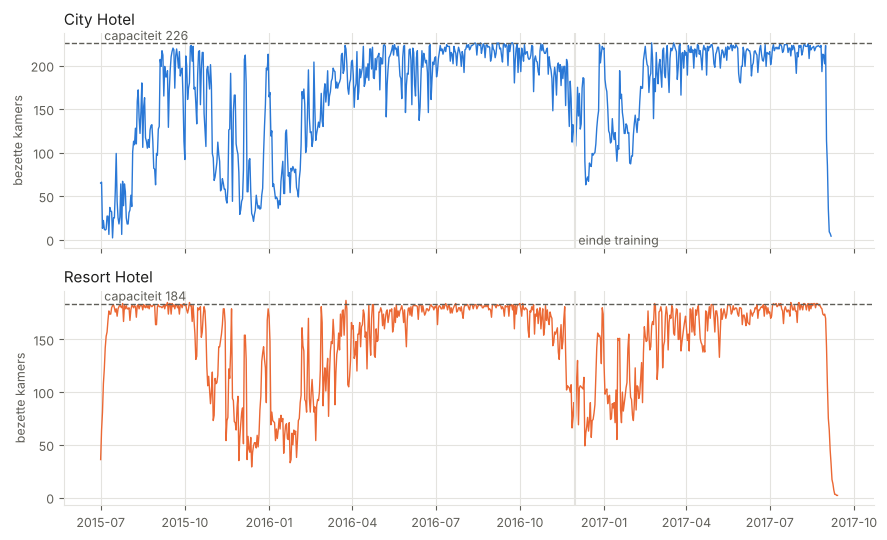

In [18]:
bezet = bezetting(ruw)
g = grenzen(cfg)
cap = capaciteit(bezet, g["training_einde"], cfg["advies"]["capaciteit_percentiel"])

fig, assen = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
for ax, (hotel, reeks) in zip(assen, bezet.groupby("hotel"), strict=True):
    ax.plot(reeks["nacht"], reeks["bezet"], color=KLEUR[hotel], linewidth=1)
    ax.axhline(cap[hotel], color=INKT_ZACHT, linewidth=1, linestyle="--")
    ax.text(
        reeks["nacht"].min(),
        cap[hotel],
        f" capaciteit {cap[hotel]:.0f}",
        color=INKT_ZACHT,
        fontsize=9,
        va="bottom",
    )
    ax.axvline(g["training_einde"], color=RASTER, linewidth=1.5)
    ax.set_ylabel("bezette kamers", color=INKT_ZACHT, fontsize=9)
    opmaak(ax, hotel)
assen[0].text(
    g["training_einde"],
    assen[0].get_ylim()[0],
    " einde training",
    color=INKT_ZACHT,
    fontsize=9,
    va="bottom",
)
plt.tight_layout()
{hotel: round(c) for hotel, c in cap.items()}

In [19]:
volgeboekt = bezet.assign(cap=bezet["hotel"].map(cap))
volgeboekt = volgeboekt[
    volgeboekt["bezet"] >= cfg["advies"]["volgeboekt_vanaf"] * volgeboekt["cap"]
]
print("Volgeboekte nachten (>= 95 % van de capaciteit), per hotel:")
print(volgeboekt.groupby("hotel").size().to_string())
print(
    "\nMaximum overboeking per nacht (5 %):",
    {hotel: int(np.floor(cfg["advies"]["max_aandeel"] * c)) for hotel, c in cap.items()},
)

Volgeboekte nachten (>= 95 % van de capaciteit), per hotel:
hotel
City Hotel      240
Resort Hotel    365

Maximum overboeking per nacht (5 %): {'City Hotel': 11, 'Resort Hotel': 9}


City komt op ongeveer 226 kamers, Resort op 184. City zit van april tot november bijna elke
nacht aan die grens, Resort vooral in de zomer. De winter is voor beide laagseizoen: daarom telt
de validatie (Q1 2017) maar 31 volgeboekte nachten, en de test (april tot augustus) 204. Op de
volgeboekte nachten levert overboeken iets op, en alleen daar telt de businessmetriek. Het
maximum van 5 % geeft 11 kamers voor City en 9 voor Resort.

Drie kanttekeningen:

- de echte capaciteit kan hoger liggen: kamers die nooit verkocht werden, zie je niet
- City ligt tot eind 2015 veel lager dan daarna, terwijl Resort vanaf juli 2015 meteen vol zit.
  Waarschijnlijk is de export van City in het begin onvolledig. Voor de capaciteit maakt dat
  weinig uit, want het 99ste percentiel komt uit de drukke maanden
- na eind augustus 2017 zakt de bezetting naar nul: daar stopt de export

## 8. De spreiding per nacht: annulaties komen samen

Als boekingen los van elkaar annuleren, is de spreiding van het aantal annulaties per nacht de
som van p × (1 − p). Een groep annuleert echter samen. Hoeveel annulaties gebeuren samen met
identieke boekingen, op dezelfde dag, voor dezelfde aankomst?

7266 late annulaties, de grootste groep telt 60 boekingen


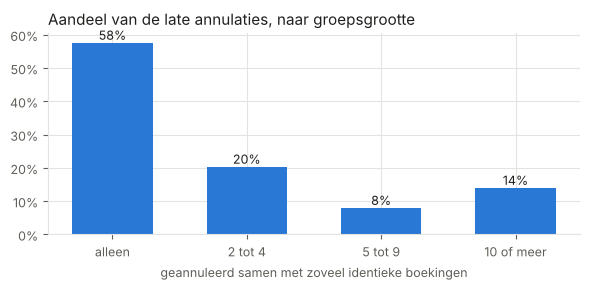

In [20]:
sleutel = [
    "hotel",
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month",
    "lead_time",
    "agent",
    "market_segment",
    "reservation_status",
    "reservation_status_date",
]
annulaties = df[df[DOEL] == 1]
grootte = annulaties.groupby(sleutel, dropna=False)[DOEL].transform("size")
klasse = pd.cut(
    grootte, [0, 1, 4, 9, np.inf], labels=["alleen", "2 tot 4", "5 tot 9", "10 of meer"]
)
verdeling = klasse.value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(verdeling.index.astype(str), verdeling.values, color=KLEUR["City Hotel"], width=0.6)
for x, v in enumerate(verdeling.values):
    ax.text(x, v, f"{v:.0%}", ha="center", va="bottom", color=INKT, fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("geannuleerd samen met zoveel identieke boekingen", color=INKT_ZACHT, fontsize=9)
opmaak(ax, "Aandeel van de late annulaties, naar groepsgrootte")
plt.tight_layout()
print(f"{len(annulaties)} late annulaties, de grootste groep telt {grootte.max()} boekingen")

58 % van de late annulaties staat alleen. Maar 22 % valt samen met minstens vier identieke
boekingen, en de grootste groep telt er 60. Voor één nacht betekent dat: als het misgaat, gaat het met tien kamers
tegelijk mis. De spreiding is dus breder dan die van losse annulaties. Het advies vangt dat op met
een spreidingsfactor per hotel, geschat op de validatie (`spreidingsfactor()` in
`src/nachten.py`). Voor het gekozen model, boosting, is ze 2,6 voor City en 1,5 voor
Resort: de echte spreiding is anderhalf tot ruim twee keer zo breed als bij losse annulaties.

## 9. Indirecte kenmerken: verwijzen segment en agent naar het land?

Het land staat uit (6). Daarmee is het niet weg: een model kan het land ook zien via kolommen die
ermee samenhangen. Twee kandidaten zijn `market_segment` en `agent`: een touroperator of een
reisagent werkt vaak voor één markt. Twee vragen:

1. Hoeveel zeggen segment en agent over het land, bij de boekingen die actief zijn op het
   beslismoment?
2. Neemt het model zonder land zo het patroon van het land over?

Het aandeel PRT staat er drie keer: bij alle actieve boekingen, bij wie uitcheckte, en bij wie na
het beslismoment annuleerde of niet kwam opdagen. Bij wie uitcheckte, is het land vermoedelijk
juist ingevuld (6).

In [21]:
def aandeel_prt(kolom):
    """Per waarde van `kolom`: aandeel PRT bij alle actieve boekingen, uitgecheckt, geannuleerd."""
    waarde = als_tekst(df[[kolom]])[kolom]
    is_prt = df["country"] == "PRT"
    uit = df[DOEL] == 0
    return pd.DataFrame(
        {
            "boekingen": waarde.value_counts(),
            "PRT": is_prt.groupby(waarde).mean(),
            "PRT, uitgecheckt": is_prt[uit].groupby(waarde[uit]).mean(),
            "PRT, geannuleerd": is_prt[~uit].groupby(waarde[~uit]).mean(),
            "annuleert": df[DOEL].groupby(waarde).mean(),
        }
    ).sort_values("boekingen", ascending=False)


print(f"Aandeel PRT bij alle actieve boekingen: {(df['country'] == 'PRT').mean():.1%}")
aandeel_prt("market_segment").round(3)

Aandeel PRT bij alle actieve boekingen: 23.1%


,boekingen,PRT,"PRT, uitgecheckt","PRT, geannuleerd",annuleert
market_segment,,,,,
Online TA,25268,0.148,0.119,0.288,0.172
Offline TA/TO,13111,0.260,0.200,0.894,0.087
Groups,7126,0.381,0.262,0.993,0.163
Direct,4487,0.308,0.280,0.540,0.107
Corporate,809,0.591,0.521,0.940,0.166
Complementary,23,0.609,0.550,1.000,0.130


In [22]:
per_agent = aandeel_prt("agent")
top = per_agent.head(10)
print(f"De tien grootste agents hebben {top['boekingen'].sum() / len(df):.0%} van de boekingen.")
print('"geen" is een boeking zonder agent.')
top.round(3)

De tien grootste agents hebben 68% van de boekingen.
"geen" is een boeking zonder agent.


,boekingen,PRT,"PRT, uitgecheckt","PRT, geannuleerd",annuleert
agent,,,,,
9.0,14699,0.084,0.079,0.104,0.198
240.0,5172,0.274,0.212,0.535,0.191
geen,3776,0.458,0.379,0.953,0.137
6.0,2053,0.300,0.240,0.994,0.079
7.0,1942,0.136,0.098,0.944,0.046
14.0,1934,0.113,0.093,0.279,0.108
1.0,1766,0.550,0.410,1.000,0.238
250.0,1409,0.388,0.358,0.636,0.109
28.0,1084,0.110,0.074,1.000,0.039


In [23]:
def auc_voor_prt(kolommen, alleen_uitgecheckt=False):
    """Hoe goed raad je PRT uit deze kolommen? Zoals in 5: het aandeel PRT per waarde, geleerd
    op de training en gemeten op de validatie."""
    sleutel_tr = als_tekst(training[kolommen]).agg("|".join, axis=1)
    sleutel_va = als_tekst(validatie[kolommen]).agg("|".join, axis=1)
    prt_tr = training["country"] == "PRT"
    prt_va = validatie["country"] == "PRT"
    score = sleutel_va.map(prt_tr.groupby(sleutel_tr).mean()).fillna(prt_tr.mean())
    if alleen_uitgecheckt:
        uit = validatie[DOEL] == 0
        prt_va, score = prt_va[uit], score[uit]
    return roc_auc_score(prt_va, score)


pd.DataFrame(
    [
        {
            "kolommen": " + ".join(k),
            "AUC voor PRT": auc_voor_prt(k),
            "alleen uitgecheckt": auc_voor_prt(k, alleen_uitgecheckt=True),
        }
        for k in [["market_segment"], ["agent"], ["market_segment", "agent"]]
    ]
).round(3)

,kolommen,AUC voor PRT,alleen uitgecheckt
0,market_segment,0.696,0.686
1,agent,0.717,0.702
2,market_segment + agent,0.702,0.682


In [24]:
# Het model zoals src.train het bouwt, zonder land. Wat voorspelt het voor PRT en voor de rest?
assert not cfg["features"]["gebruik_land"]
model_zonder_land, _ = train(df, cfg)
kans = model_zonder_land.predict_proba(validatie[invoerkolommen(cfg)])[:, 1]
prt_va = (validatie["country"] == "PRT").to_numpy()
y_va = validatie[DOEL].to_numpy()
pd.DataFrame(
    {
        "boekingen": [prt_va.sum(), (~prt_va).sum()],
        "gemiddelde kans": [kans[prt_va].mean(), kans[~prt_va].mean()],
        "echt aandeel": [y_va[prt_va].mean(), y_va[~prt_va].mean()],
        "voorspeld/echt": [
            kans[prt_va].sum() / y_va[prt_va].sum(),
            kans[~prt_va].sum() / y_va[~prt_va].sum(),
        ],
    },
    index=["PRT", "rest"],
).round(3)

,boekingen,gemiddelde kans,echt aandeel,voorspeld/echt
PRT,750,0.123,0.327,0.378
rest,3689,0.154,0.134,1.150


**Segment en agent verwijzen naar het land. Het model zonder land neemt het lek toch niet over.**

- **Ze zeggen iets over het land.** Bij wie uitcheckte, loopt het aandeel PRT van 12 % (Online TA)
  tot 52 % (Corporate), en bij de grote agents van 8 % (agent 9) tot 41 % (agent 1). Uit segment
  of agent alleen raad je PRT met een AUC van ongeveer 0,70, ook als je alleen kijkt naar wie
  uitcheckte. Het land weglaten maakt het model dus niet blind voor het land.
- **Binnen één agent duikt het patroon van 6 opnieuw op.** Bij agent 28 is 7 % van wie uitcheckte
  Portugees, en 100 % van wie annuleerde. Bij agent 6 is dat 24 tegenover 99 %, bij agent 7 10
  tegenover 94 %, bij agent 241 12 tegenover 97 %. Het segment en de agent verklaren dat niet:
  binnen dezelfde agent zou het land van wie annuleert en van wie uitcheckt ongeveer gelijk moeten
  zijn. Dat versterkt bevinding 1: het land wordt pas na het beslismoment ingevuld.
- **Het model volgt het land niet.** Het geeft een Portugese boeking gemiddeld een lagere kans
  (12,3 %) dan de rest (15,4 %), terwijl de Portugese boekingen veel vaker annuleren (32,7 %
  tegenover 13,4 %). Voorspeld/echt is 0,38 voor PRT en 1,15 voor de rest, dezelfde cijfers als
  bevinding 2 in de README.

Wat dit betekent voor de controle per groep (bevinding 2): de sterke onderschatting van PRT komt
niet doordat het model via segment of agent toch naar het land kijkt. Ze komt doordat de groep
zelf gemaakt is met de kolom die lekt. "PRT" betekent deels "kwam niet opdagen", en dat kan geen
model voorspellen zonder het label. Met deze export blijft die controle dus onbruikbaar. En omdat
segment en agent wel naar het land wijzen, volstaat het land weglaten niet voor een eerlijk model.
Met een land dat bij het boeken gekend is, moet een controle per groep ook nagaan wat segment en
agent per land doen.

## 10. Lek via adr: geboekt tarief of achteraf aangepast?

`adr` is de gemiddelde prijs per nacht. Volgens de bron (Antonio et al., 2019) is dat de som van
alle verblijfstransacties gedeeld door het aantal nachten. Bij wie uitcheckte, kan dat dus de
prijs ná het verblijf zijn, met kortingen, upgrades of extra's. Bij een annulatie is er geen
verblijf. Zet het hotel de prijs van een annulatie op 0, of vult het ze anders in, dan verraadt
`adr` de afloop, net als het land. Vier controles:

1. Zijn er geannuleerde boekingen met adr 0?
2. Lijkt de verdeling bij geannuleerd en uitgecheckt op elkaar, per hotel, segment en maand?
3. Binnen hetzelfde hotel, dezelfde maand, hetzelfde segment en kamertype: ligt de prijs van wie
   annuleert anders?
4. Is er een ander afwijkend patroon, en gebruikt het model het?

In [25]:
# 1. adr 0 of minder, in de ruwe export: schoon_op() haalt die eruit, dus hier vóór het opschonen.
nul = ruw["adr"] <= 0
geen_gratis = ruw["market_segment"] != "Complementary"
pd.DataFrame(
    {
        "boekingen": ruw["reservation_status"].value_counts(),
        "adr ≤ 0": nul.groupby(ruw["reservation_status"]).mean(),
        "adr ≤ 0, zonder Complementary": nul[geen_gratis]
        .groupby(ruw.loc[geen_gratis, "reservation_status"])
        .mean(),
    }
).round(4)

,boekingen,adr ≤ 0,"adr ≤ 0, zonder Complementary"
reservation_status,,,
Canceled,43017,0.0043,0.0025
Check-Out,75166,0.0232,0.0156
No-Show,1207,0.0215,0.0126


In [26]:
# 2. De verdeling bij de actieve boekingen, per hotel. No-show staat apart.
df.groupby(["hotel", "reservation_status"])["adr"].describe()[
    ["count", "25%", "50%", "75%", "mean"]
].round(1)

count   25%    50%    75%   mean
hotel        reservation_status                                    
City Hotel   Canceled             4757.0  80.0   99.9  125.1  106.7
             Check-Out           28082.0  80.8  100.0  124.0  106.4
             No-Show               468.0  75.0   87.6  117.2   98.4
Resort Hotel Canceled             1922.0  56.0   83.2  140.0  105.5
             Check-Out           15476.0  57.6   81.8  129.0   99.7
             No-Show               119.0  48.0   74.2  110.1   87.1

In [27]:
per_segment = df.groupby(["market_segment", DOEL])["adr"].median().unstack()
per_segment.columns = ["mediaan, uitgecheckt", "mediaan, geannuleerd"]
per_segment.join(df.groupby("market_segment").size().rename("boekingen")).round(1)

,"mediaan, uitgecheckt","mediaan, geannuleerd",boekingen
market_segment,,,
Complementary,20.0,20.0,23
Corporate,67.0,52.2,809
Direct,119.0,115.4,4487
Groups,73.2,69.0,7126
Offline TA/TO,85.0,89.1,13111
Online TA,108.9,109.8,25268


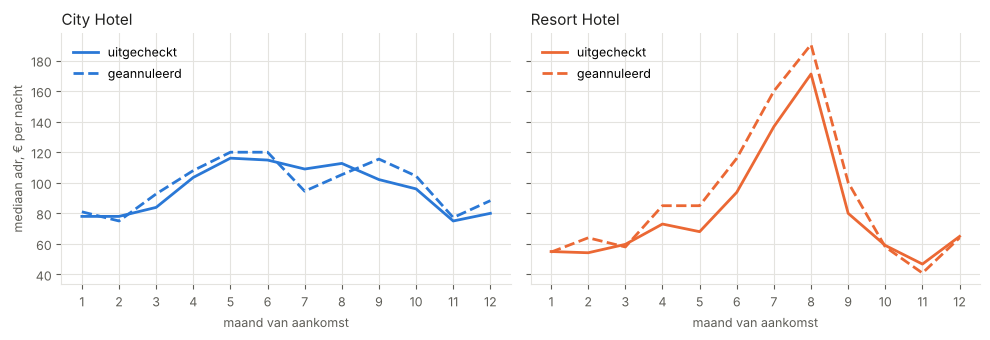

In [28]:
MAANDEN = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]
fig, assen = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (hotel, deel) in zip(assen, df.groupby("hotel"), strict=True):
    mediaan = deel.groupby(["arrival_date_month", DOEL])["adr"].median().unstack().reindex(MAANDEN)
    for label, stijl, wat in [(0, "-", "uitgecheckt"), (1, "--", "geannuleerd")]:
        ax.plot(range(1, 13), mediaan[label], stijl, color=KLEUR[hotel], linewidth=2, label=wat)
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("maand van aankomst", color=INKT_ZACHT, fontsize=9)
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    opmaak(ax, hotel)
assen[0].set_ylabel("mediaan adr, € per nacht", color=INKT_ZACHT, fontsize=9)
plt.tight_layout()

In [29]:
# 3. De prijs gedeeld door de mediaan van zijn groep: hotel, jaar, maand, segment en kamertype.
# Is het tarief bij een annulatie anders ingevuld, dan ligt die verhouding anders dan 1.
groep = ["hotel", "arrival_date_year", "arrival_date_month", "market_segment", "reserved_room_type"]
relatief = df["adr"] / df.groupby(groep)["adr"].transform("median")
print(
    relatief.groupby(df["reservation_status"]).describe()[["count", "25%", "50%", "75%"]].round(3)
)

auc_adr = roc_auc_score(validatie[DOEL], validatie["adr"])
auc_relatief = roc_auc_score(validatie[DOEL], relatief[validatie.index])
print(f"\nAUC op de validatie: adr alleen {auc_adr:.3f}, adr binnen zijn groep {auc_relatief:.3f}")

                      count    25%    50%    75%
reservation_status                              
Canceled             6679.0  0.923  1.000  1.114
Check-Out           43558.0  0.886  1.000  1.125
No-Show               587.0  0.895  0.988  1.064

AUC op de validatie: adr alleen 0.557, adr binnen zijn groep 0.531


In [30]:
# 4. Een ander patroon: een rond bedrag, zonder cent. Een prijs per nacht die achteraf herrekend
# is over een verblijf, is zelden rond. Een geboekt tarief vaker.
rond = df["adr"] % 1 == 0
zonder_wijziging = df["booking_changes"] == 0
pd.DataFrame(
    {
        "City Hotel": rond[df["hotel"] == "City Hotel"].groupby(df["reservation_status"]).mean(),
        "Resort Hotel": rond[df["hotel"] == "Resort Hotel"]
        .groupby(df["reservation_status"])
        .mean(),
        "beide": rond.groupby(df["reservation_status"]).mean(),
        "beide, nooit gewijzigd": rond[zonder_wijziging]
        .groupby(df.loc[zonder_wijziging, "reservation_status"])
        .mean(),
    }
).round(3)

,City Hotel,Resort Hotel,beide,"beide, nooit gewijzigd"
reservation_status,,,,
Canceled,0.424,0.633,0.484,0.484
Check-Out,0.405,0.432,0.415,0.402
No-Show,0.457,0.496,0.465,0.431


In [31]:
# Gebruikt het model dat? Drie keer dezelfde validatie als src.train: met adr, met adr afgerond
# op de euro (dan is het verschil tussen rond en niet rond weg), en zonder adr.
zonder_adr = copy.deepcopy(cfg)
zonder_adr["features"]["numeriek"] = [k for k in cfg["features"]["numeriek"] if k != "adr"]
varianten = {
    "met adr": valideer(df, cfg),
    "adr afgerond op de euro": valideer(df.assign(adr=df["adr"].round()), cfg),
    "zonder adr": valideer(df, zonder_adr),
}
pd.DataFrame(
    {naam: {"AUC": v["auc"], "MAE per hotel-nacht": v["mae"]} for naam, v in varianten.items()}
).T.round(3)

,AUC,MAE per hotel-nacht
met adr,0.687,4.856
adr afgerond op de euro,0.682,4.828
zonder adr,0.683,5.047


**`adr` is het geboekte tarief en niet achteraf aangepast bij een annulatie. Het mag een
feature blijven.**

1. **Geen nullen bij annulaties.** Een adr van 0 of minder komt bij geannuleerde boekingen minder
   voor (0,4 %) dan bij wie uitcheckte (2,3 %), ook zonder de gratis kamers van Complementary
   (0,25 tegenover 1,6 %). Het hotel zet de prijs van een annulatie dus niet op 0.
2. **De verdelingen overlappen.** Per hotel liggen de medianen bij geannuleerd en uitgecheckt
   minder dan 2 € uit elkaar (City 99,9 en 100,0, Resort 83,2 en 81,8). Per segment wijkt alleen
   Corporate duidelijk af (52 tegenover 67, 809 boekingen). Per maand volgen beide lijnen het
   seizoen. In het resort ligt de prijs van wie annuleert in de zomer hoger (augustus 190
   tegenover 171): duur boeken in het hoogseizoen gaat samen met vaker annuleren. Dat is gedrag,
   en die prijs is gekend bij het boeken.
3. **Binnen dezelfde groep geen verschil.** Gedeeld door de mediaan van hotel, jaar, maand,
   segment en kamertype ligt de prijs bij geannuleerd en uitgecheckt allebei op een mediaan van
   1,00. De AUC zakt dan van 0,557 naar 0,531: wat adr over de afloop zegt, is vooral seizoen en
   segment.
4. **Eén afwijkend patroon: ronde bedragen.** Geannuleerde boekingen hebben vaker een prijs
   zonder cent (48 tegenover 42 %, in het resort 63 tegenover 43 %), ook als ze nooit gewijzigd
   werden. Dat past bij de definitie: bij wie uitcheckte, wordt de prijs herrekend uit wat er
   tijdens het verblijf betaald werd, bij een annulatie blijft het geboekte tarief staan. Het
   model haalt daar niets uit: met adr afgerond op de euro is de AUC 0,682 in plaats van 0,687 en
   de MAE 4,83 in plaats van 4,86. Zonder adr stijgt de MAE naar 5,05.

Er verandert niets aan de features. Eén kanttekening voor deel 3: bij wie uitcheckte, kan de adr in
de training licht afwijken van wat er op het beslismoment in het boekingssysteem stond. In
productie krijgt het model het tarief van dat moment.

## 11. Wat dit betekent voor het model

| Vaststelling | Keuze | Waar |
|---|---|---|
| annulatie verschuift met seizoen en jaar | split in de tijd, met embargo | `src/train.py`, `grenzen()` |
| adr ≤ 0 of ≥ 1 000, 0 nachten | uitgesloten | `schoon_op()` |
| Non Refund: 99,4 % geannuleerd, geen gedrag | uitgesloten, na onderzoek | `schoon_op()` |
| alleen late annulaties maken een kamer vrij | label op het beslismoment, 14 % | `maak_label()` |
| parkeerplaats, toegewezen kamer, wijzigingen, speciale wensen pas bij aankomst | geen features | `configs/default.yaml` |
| het land is waarschijnlijk pas bij inchecken ingevuld | geen feature | `features.gebruik_land` |
| segment en agent wijzen naar het land (AUC ≈ 0,70), het model volgt het land niet | land blijft uit, controle per groep onbruikbaar | bevinding 2 in de README |
| adr van een annulatie is het geboekte tarief, niet op 0 gezet | adr blijft een feature | `features.numeriek` |
| dubbele rijen zijn groepen, en groepen annuleren samen | blijven staan, spreidingsfactor | `src/nachten.py` |
| geen kamertal in de data | capaciteit = p99 van de bezetting | `capaciteit()` |
| een export met een onmogelijk aandeel annulaties | geweigerd door het schema | `src/schema.py` |